# GRID

## My focus

- Takes atomic coordinates as input these are calculated using a mathematical method called Unrestricted Hartree Fock(not done with Grid)
- Uses GuassLegendre quadrature to create integrated points and weights
- BeckeRTransform transforms the weights and points to a radial scale
- Create a grid with those points and weights
- Find the electron density averages
- Create splines to create estimates in between the calculated average density at given points

In [29]:
from iodata import load_one

mol = load_one("He_t.fchk")

center = mol.atcoords.flatten()
print(f"Atomic Coordinates: {mol.atcoords}")
print(f"Atomic numbers    : {mol.atnums}")
print(f"Alpha MO occupations: {mol.mo.occsa}")
print(f"Beta MO occupations : {mol.mo.occsb}")

Atomic Coordinates: [[0. 0. 0.]]
Atomic numbers    : [2]
Alpha MO occupations: [1. 1.]
Beta MO occupations : [0. 0.]


In [35]:
import numpy as np
from grid import GaussLegendre, BeckeRTransform, AtomGrid

# get 50 points and weights with Guass-legendre
oned = GaussLegendre(npoints=50)

#makes the grid radial
rgrid = BeckeRTransform(0.0, R=1.5).transform_1d_grid(oned)

print(f"Radial grid size : {rgrid.size}")
print(f"Radial grid r_min: {np.min(rgrid.points):.5f}")
print(f"Radial grid r_max: {np.max(rgrid.points):.5f}\n")

# construct atomic grid
atgrid = AtomGrid(rgrid, degrees=[22], center=center)

# atomic grid size = (radial grid size) * (angular grid size)
print(f"AtomGrid size          : {atgrid.size}")
print(f"AtomGrid points shape  : {atgrid.points.shape}")
print(f"AtomGrid weights shape : {atgrid.weights.shape}")
print(f"AtomGrid radial size   : {atgrid.rgrid.size}")
print(f"AtomGrid angular degree: {atgrid.degrees}")
print(f"AtomGrid center        : {atgrid.center}")

Radial grid size : 50
Radial grid r_min: 0.00085
Radial grid r_max: 2644.94645

AtomGrid size          : 9700
AtomGrid points shape  : (9700, 3)
AtomGrid weights shape : (9700,)
AtomGrid radial size   : 50
AtomGrid angular degree: [23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23, 23]
AtomGrid center        : [0. 0. 0.]


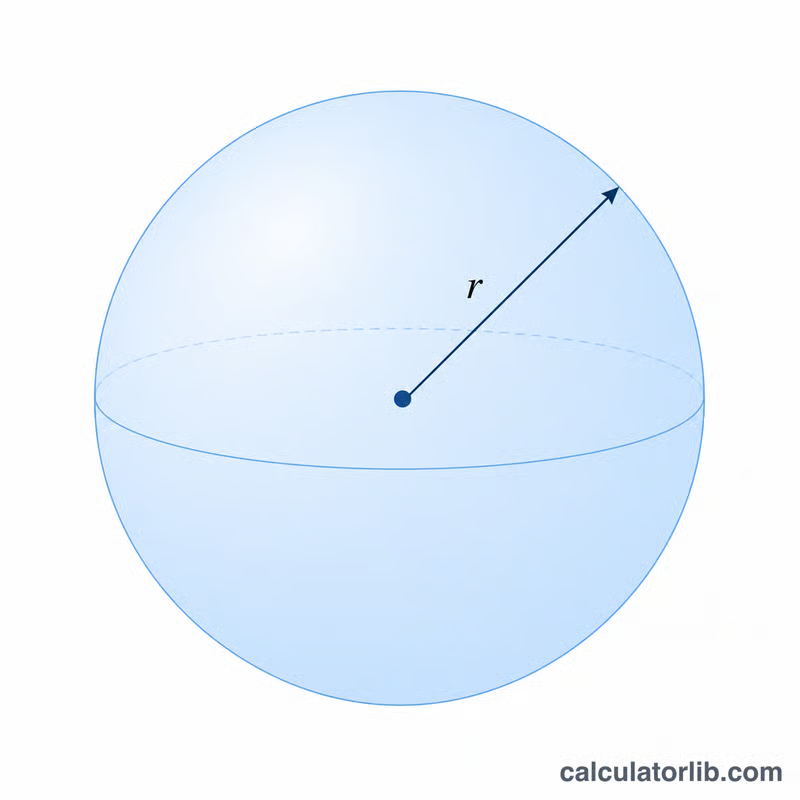

In [36]:
from gbasis.wrappers import from_iodata
from gbasis.evals.density import evaluate_density

# Check that the atomic grid is centered at the position of atomic nucleus
assert np.all(mol.atcoords == atgrid.center)

# Construct molecular basis from wave-function information read by IOData
basis = from_iodata(mol)

# Evaluate the electron density on the grid points
rdm = mol.one_rdms["scf"]
dens = evaluate_density(rdm, basis, atgrid.points)
print(f"Shape of electron density array : {dens.shape}")

# Integrate electron density
print(f"Number of electrons in molecule : {np.sum(mol.atnums) - mol.charge}")
print(f"Integral of the electron density: {atgrid.integrate(dens)}")

Shape of electron density array : (9700,)
Number of electrons in molecule : 2.0
Integral of the electron density: 1.999999992681273


Angular Integral calculated with Lebedev-Laikov Quadrature: 

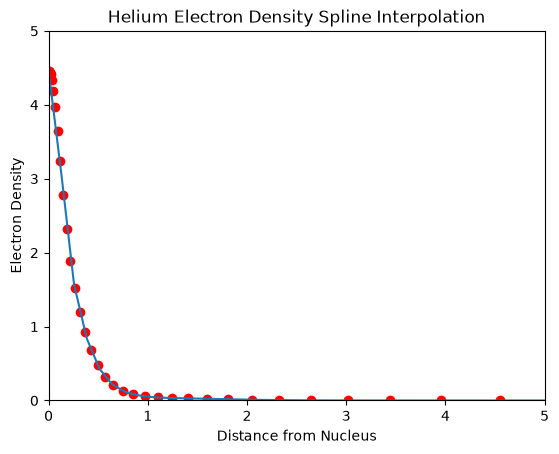

In [41]:
import matplotlib.pyplot as plt

spline = atgrid.spherical_average(dens)

original_radial = atgrid.rgrid.points

#create 20 points between 0 and 5 of the radial points
new_radial = np.linspace(0, 5, 40)

new_density = spline(new_radial)

plt.plot(new_radial, new_density, label = "Spline")
plt.scatter(original_radial, spline(original_radial), label = "Original Points", color = "red")
plt.title("Helium Electron Density Spline Interpolation")
plt.xlabel("Distance from Nucleus")
plt.ylabel("Electron Density")
plt.xlim(0,5)
plt.ylim(0,5)
plt.show()

Ideas for Project: 
1. Test the accuracy of the splines dependent on the number of points chosen. This would result in a graph with the number of points on the x-axis and the error on the y-axis.
2. Compare the use of Guass-Legendre Quadrature to the Trapezoid Rule. The graph would be a graph with number of points on the x-axis and error on the y-axis with the two different methods graphed for comparison.

Works Cited:
Grid: A Python library for molecular integration, interpolation, differentiation, and more. Alireza Tehrani, Xiaotian Derrick Yang, Marco Martínez-González, Leila Pujal, Raymundo Hernández-Esparza, Matthew Chan, Esteban Vöhringer-Martinez, Toon Verstraelen, Paul W. Ayers, Farnaz Heidar-Zadeh. J. Chem. Phys. 160 (17), 172503 (2024). https://doi.org/10.1063/5.0202240

https://en.wikipedia.org/wiki/Lebedev_quadrature